<a href="https://colab.research.google.com/github/nfathimmain-sketch/FATHIMA-N-_EXIT-EXAM-/blob/main/pokemon's_primary__battle_type(1)_G2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TASK-1**

In [14]:
#Data Understanding and Exploration
import pandas as pd
import numpy as np



In [7]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/DSA/Exit_exam/raw_data/G2.csv")
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [13]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type1,type2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [15]:


print("\nInfo:")
print(df.info())


Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type1            1351 non-null   object 
 6   type2            765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB
None


In [16]:

print("\nMissing Values per Column:")
print(df.isnull().sum())


Missing Values per Column:
id                   0
name                 0
height_dm            0
weight_hg            0
base_experience     49
type1                0
type2              586
hp                   0
attack               0
defense              0
dtype: int64


In [17]:

print("\nTarget (type1) Counts:")
print(df["type1"].value_counts(dropna=False))


Target (type1) Counts:
type1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
dragon       59
steel        52
poison       52
ghost        52
ground       50
ice          44
fairy        35
flying       13
Name: count, dtype: int64


In [18]:

print("\nSecondary Type (type2) Missing Counts:")
print("NaN in type2:", df["type2"].isna().sum())


Secondary Type (type2) Missing Counts:
NaN in type2: 586


In [19]:
# Detailed Summary Statistics
candidate_num_cols = [
    "height_dm", "weight_hg", "base_experience",
    "hp", "attack", "defense", "sp_attack", "sp_defense", "speed"
]
num_cols = [c for c in candidate_num_cols if c in df.columns]

print("Numerical Summary:")
print(df[num_cols].describe().round(2))

print("\nUnique Primary Types (type1):", df["type1"].nunique(dropna=True))
print("Unique Secondary Types (type2):", df["type2"].nunique(dropna=True))

Numerical Summary:
       height_dm  weight_hg  base_experience       hp   attack  defense
count    1351.00    1351.00          1302.00  1351.00  1351.00  1351.00
mean       20.44     991.06           161.94    71.67    82.76    76.19
std        53.24    1953.12            82.53    26.83    32.35    30.71
min         1.00       0.00            36.00     1.00     5.00     5.00
25%         6.00      94.50            71.00    55.00    60.00    55.00
50%        11.00     326.00           165.00    70.00    80.00    70.00
75%        17.00     853.50           222.50    85.00   102.50    95.00
max      1000.00   10000.00           608.00   255.00   190.00   250.00

Unique Primary Types (type1): 18
Unique Secondary Types (type2): 18


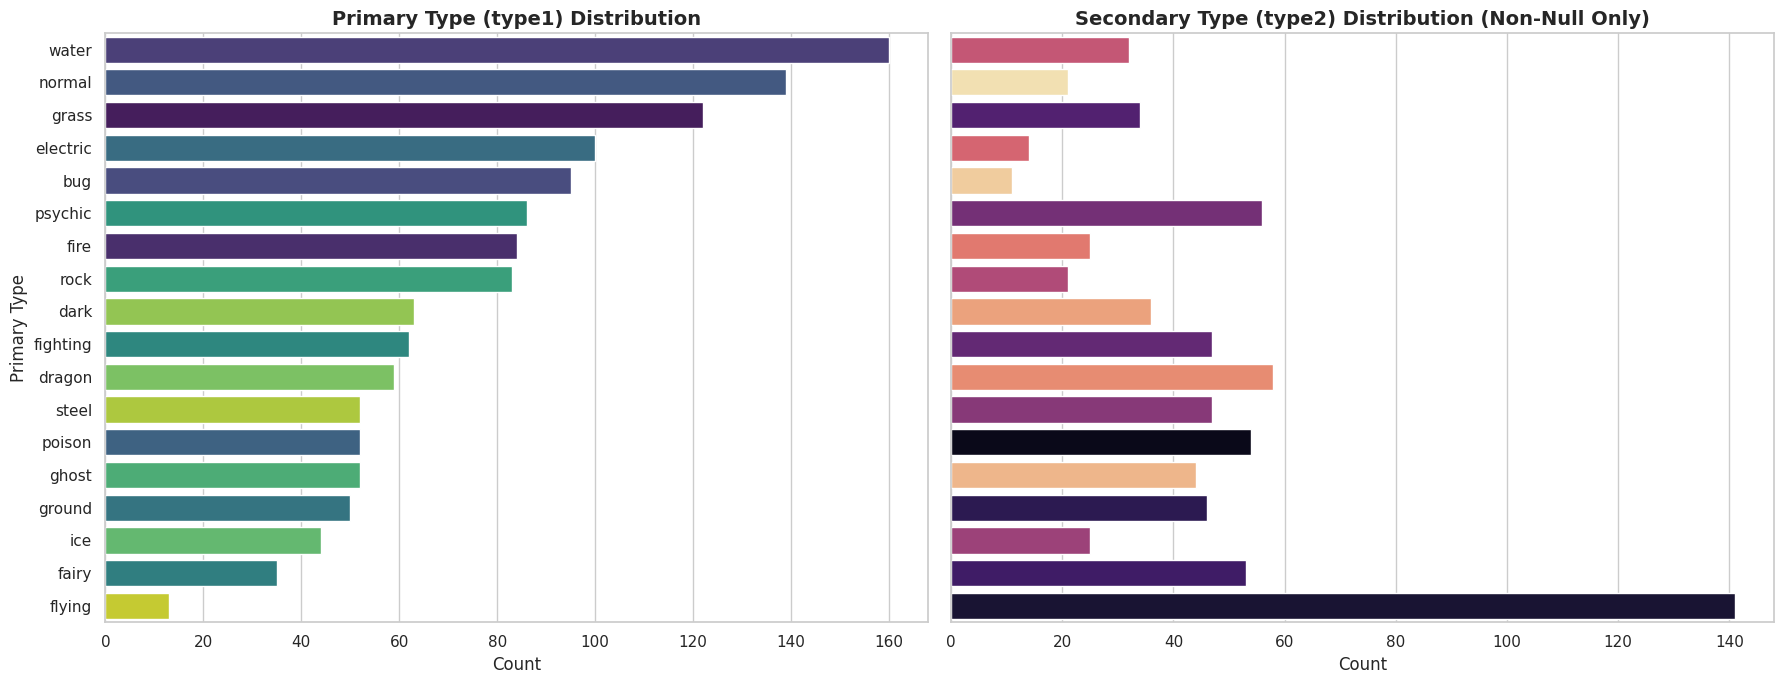

In [37]:
#distribution of pokemon types
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting theme
sns.set_theme(style="whitegrid")

# Create a side-by-side subplot to compare Type 1 and Type 2 distributions
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Primary Type Distribution
type1_order = df["type1"].value_counts().index
sns.countplot(
    data=df,
    y="type1",
    order=type1_order,
    hue="type1",
    palette="viridis",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Primary Type (type1) Distribution", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Count", fontsize=12)
axes[0].set_ylabel("Primary Type", fontsize=12)

# Secondary Type Distribution
# Filtering out missing values to plot actual distributions
type2_data = df.dropna(subset=["type2"])
type2_order = type2_data["type2"].value_counts().index
sns.countplot(
    data=type2_data,
    y="type2",
    order=type2_order,
    hue="type2",
    palette="magma",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Secondary Type (type2) Distribution (Non-Null Only)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Count", fontsize=12)
axes[1].set_ylabel("", fontsize=12) # Share y-axis label

plt.tight_layout()
plt.show()

In [ ]:
# Identify the most frequent primary pokemon type
most_frequent_type = df["type1"].value_counts().idxmax()
frequent_type_count = df["type1"].value_counts().max()

print(f"The Pokémon type that appears most frequently is: {most_frequent_type.capitalize()} with {frequent_type_count} occurrences.")

1.The pokemon type that appears most frequently ,In the provided sample rows, grass appears most frequently as the primary type (type1) with 3 entries, followed by fire with 2 entries. Across a full Poké dataset, check df["type1"].value_counts(), where water or normal typically leads.


2.Numerical feature with greatest variation: weight_hg (followed by base_experience) shows the widest spread and highest variance, jumping from 69 to 1,000 in the sample alone and spanning extreme heavy/light outliers across the full dataset. Compared to height_dm, hp, attack, and defense, its right-skewed distribution benefits most from log transformation.

3.initial observations can you make about dataset is
Heights and weights are stored in raw PokéAPI units (height_dm in decimeters and weight_hg in hectograms), while evolutionary lines show steady increases in stats, size, and base_experience.type2 contains NaNs for single-typed Pokémon and should be excluded alongside id and name to avoid leakage when predicting type1

**Task-2**

In [20]:

#Data Preprocessing and Feature Engineering
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE_STATS = [c for c in ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed"] if c in df.columns]
RAW_NUM_COLS = [c for c in ["height_dm", "weight_hg", "base_experience"] + BASE_STATS if c in df.columns]



In [22]:
# Keep rows with valid type1 and filter out classes with < 2 samples for stratified split
data = df[["type1"] + RAW_NUM_COLS].dropna(subset=["type1"]).copy()
data["type1"] = data["type1"].astype(str).str.strip().str.capitalize()

counts = data["type1"].value_counts()
data = data[data["type1"].isin(counts[counts >= 2].index)].copy()

def engineer_features(frame: pd.DataFrame, medians: dict | None = None):
    out = frame.copy()
    med_map = {} if medians is None else medians

    for col in RAW_NUM_COLS:
        out[col] = pd.to_numeric(out[col], errors="coerce")
        if medians is None:
            med_map[col] = float(out[col].median())
        out[col] = out[col].fillna(med_map[col])

    # Convert PokéAPI units: decimeters -> meters, hectograms -> kilograms
    if "height_dm" in out.columns:
        out["height_m"] = (out["height_dm"] / 10.0).clip(lower=0.1)
    if "weight_hg" in out.columns:
        out["weight_kg"] = (out["weight_hg"] / 10.0).clip(lower=0.1)

    # Physical features
    if {"height_m", "weight_kg"}.issubset(out.columns):
        out["bmi"] = out["weight_kg"] / (out["height_m"] ** 2)
        out["log_weight"] = np.log1p(out["weight_kg"])
        out["log_height"] = np.log1p(out["height_m"])

    # Combat stat totals & ratios
    if len(BASE_STATS) >= 2:
        out["stat_sum"] = out[BASE_STATS].sum(axis=1)
        for s in BASE_STATS:
            out[f"{s}_share"] = out[s] / (out["stat_sum"] + 1e-6)

    if {"attack", "defense"}.issubset(out.columns):
        out["atk_def_ratio"] = out["attack"] / (out["defense"] + 1.0)
        out["atk_def_diff"] = out["attack"] - out["defense"]

    if {"hp", "defense"}.issubset(out.columns):
        out["bulk_index"] = out["hp"] + out["defense"]

    if {"base_experience", "stat_sum"}.issubset(out.columns):
        out["xp_per_stat"] = out["base_experience"] / (out["stat_sum"] + 1.0)

    drop_raw = [c for c in ["height_dm", "weight_hg"] if c in out.columns]
    X = out.drop(columns=drop_raw + ["type1"], errors="ignore")
    return X, med_map

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(data["type1"])
X_raw_all = data.drop(columns=["type1"])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

X_train, train_medians = engineer_features(X_train_raw, medians=None)
X_test, _ = engineer_features(X_test_raw, medians=train_medians)
feature_columns = list(X_train.columns)

print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)
print("Features:", feature_columns)

X_train shape: (1080, 17) | X_test shape: (271, 17)
Features: ['base_experience', 'hp', 'attack', 'defense', 'height_m', 'weight_kg', 'bmi', 'log_weight', 'log_height', 'stat_sum', 'hp_share', 'attack_share', 'defense_share', 'atk_def_ratio', 'atk_def_diff', 'bulk_index', 'xp_per_stat']


1.why is preprocessing essential for model training?
Preprocessing cleans raw data into a consistent, leakage-free format so machine learning algorithms can learn patterns rather than noise or artifacts. In our Pokémon pipeline, converting height_dm and weight_hg to standard metric units, imputing missing values using training-only medians, engineering stat ratios/log features, scaling features for linear/SVM models, and using a stratified split prevent data leakage and keep rare types fairly represented during evaluation.


2.how didi you handle missing value in type_2 why?

I excluded type2 rather than imputing its missing (NaN) values as a model input feature. In Pokédex data, NaN in type2 usually means a Pokémon has only a single type rather than a missing measurement, and keeping type2 as a feature can leak typing and form information when the goal is predicting type1 from physical attributes and statistics.


**Task-3**

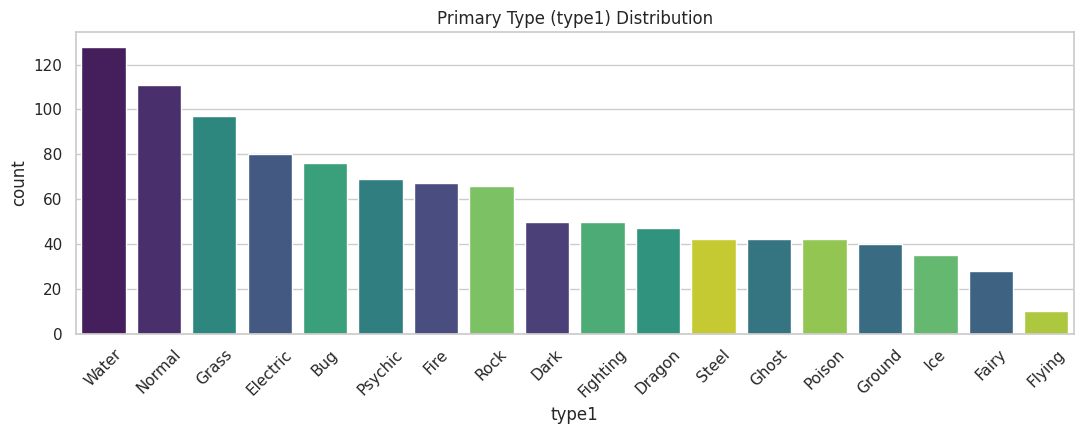

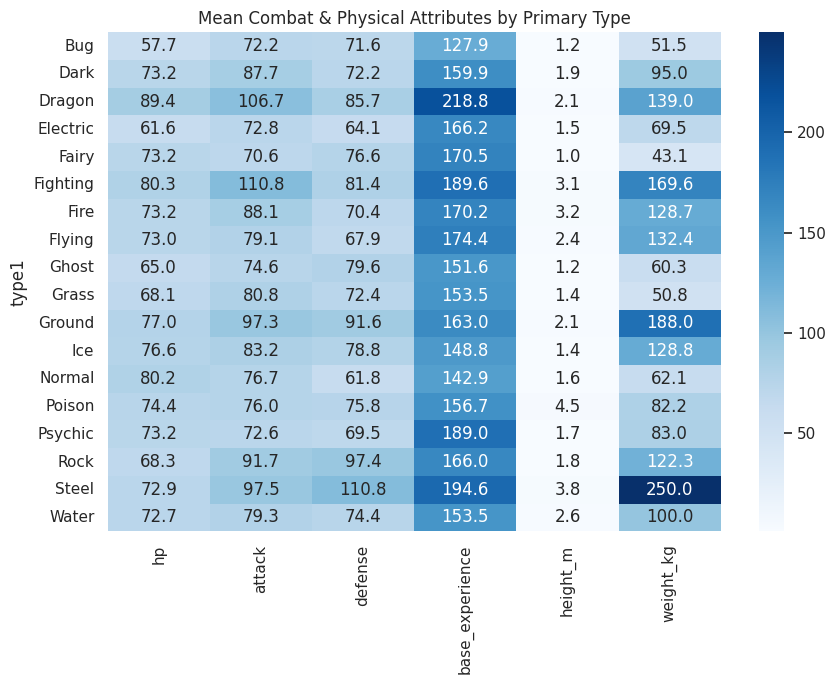

In [23]:
#EDA Type Counts and Attribute Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
eda_df = X_train.copy()
eda_df["type1"] = label_encoder.inverse_transform(y_train)

# Plot 1: Primary Type counts
plt.figure(figsize=(11, 4.5))
type_order = eda_df["type1"].value_counts().index
sns.countplot(data=eda_df, x="type1", order=type_order, hue="type1", palette="viridis", legend=False)
plt.title("Primary Type (type1) Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Mean attributes by primary type
heat_cols = [c for c in ["hp", "attack", "defense", "base_experience", "height_m", "weight_kg"] if c in eda_df.columns]
plt.figure(figsize=(9, 7))
sns.heatmap(eda_df.groupby("type1")[heat_cols].mean(), annot=True, fmt=".1f", cmap="Blues")
plt.title("Mean Combat & Physical Attributes by Primary Type")
plt.tight_layout()
plt.show()

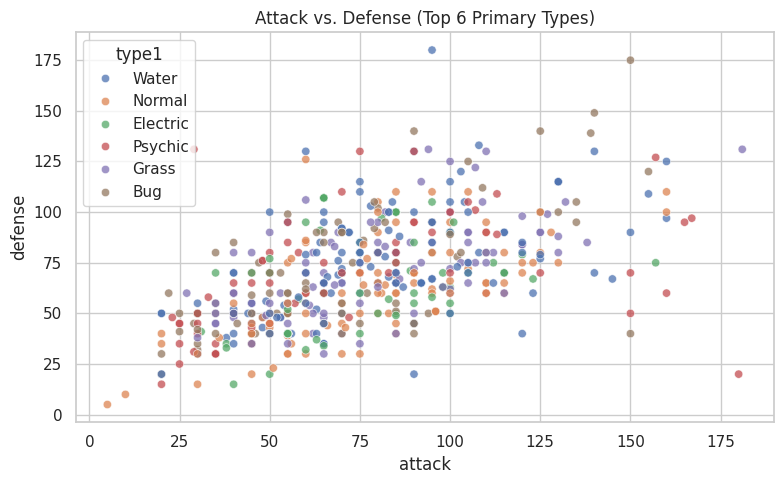

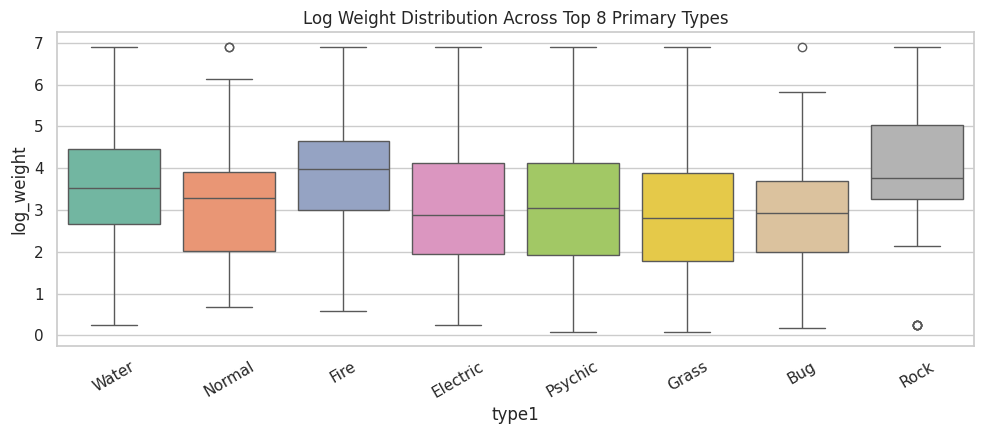

In [24]:
#  EDA - Attack vs Defense & Log Weight
if {"attack", "defense"}.issubset(eda_df.columns):
    top_types = eda_df["type1"].value_counts().head(6).index
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=eda_df[eda_df["type1"].isin(top_types)],
        x="attack", y="defense", hue="type1", alpha=0.75
    )
    plt.title("Attack vs. Defense (Top 6 Primary Types)")
    plt.tight_layout()
    plt.show()

if "log_weight" in eda_df.columns:
    top_types = eda_df["type1"].value_counts().head(8).index
    plt.figure(figsize=(10, 4.5))
    sns.boxplot(
        data=eda_df[eda_df["type1"].isin(top_types)],
        x="type1", y="log_weight", hue="type1", palette="Set2", legend=False
    )
    plt.title("Log Weight Distribution Across Top 8 Primary Types")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

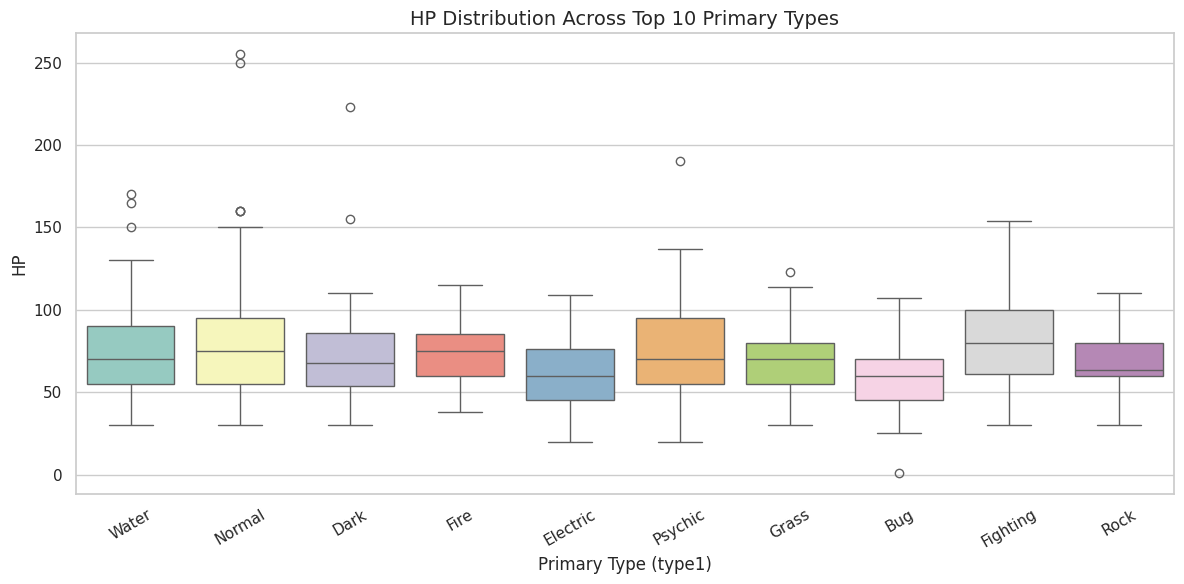

In [26]:
# Visualize HP distribution across top Pokémon types
if "hp" in eda_df.columns:
    top_types = eda_df["type1"].value_counts().head(10).index
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=eda_df[eda_df["type1"].isin(top_types)],
        x="type1", y="hp", hue="type1", palette="Set3", legend=False
    )
    plt.title("HP Distribution Across Top 10 Primary Types", fontsize=14)
    plt.xlabel("Primary Type (type1)", fontsize=12)
    plt.ylabel("HP", fontsize=12)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

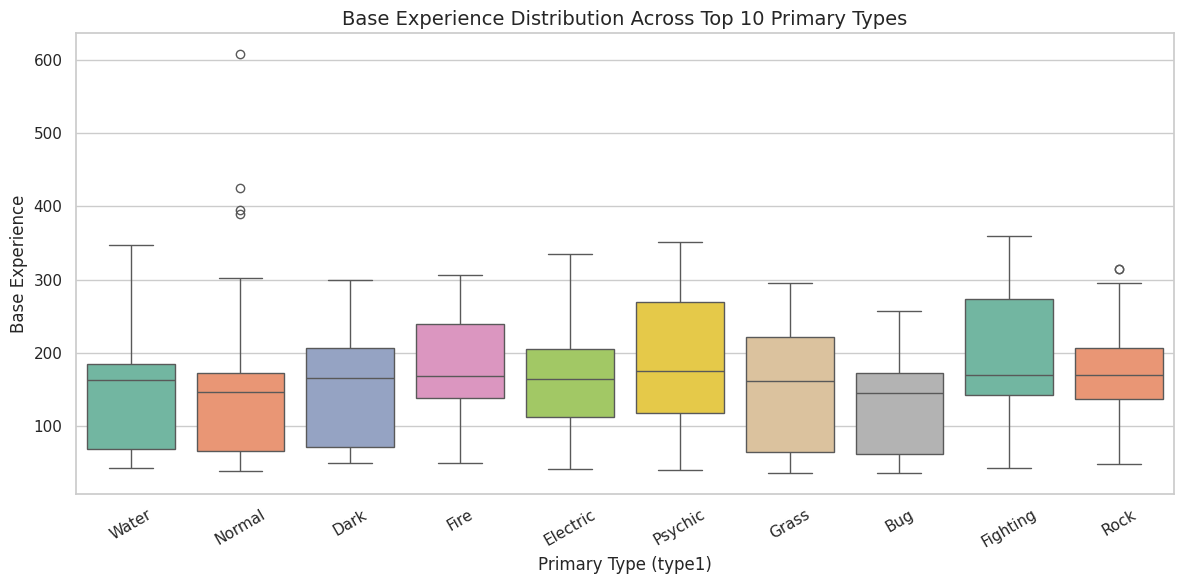

In [27]:
# Visualize Base Experience distribution across top Pokémon types
if "base_experience" in eda_df.columns:
    top_types = eda_df["type1"].value_counts().head(10).index
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=eda_df[eda_df["type1"].isin(top_types)],
        x="type1", y="base_experience", hue="type1", palette="Set2", legend=False
    )
    plt.title("Base Experience Distribution Across Top 10 Primary Types", fontsize=14)
    plt.xlabel("Primary Type (type1)", fontsize=12)
    plt.ylabel("Base Experience", fontsize=12)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

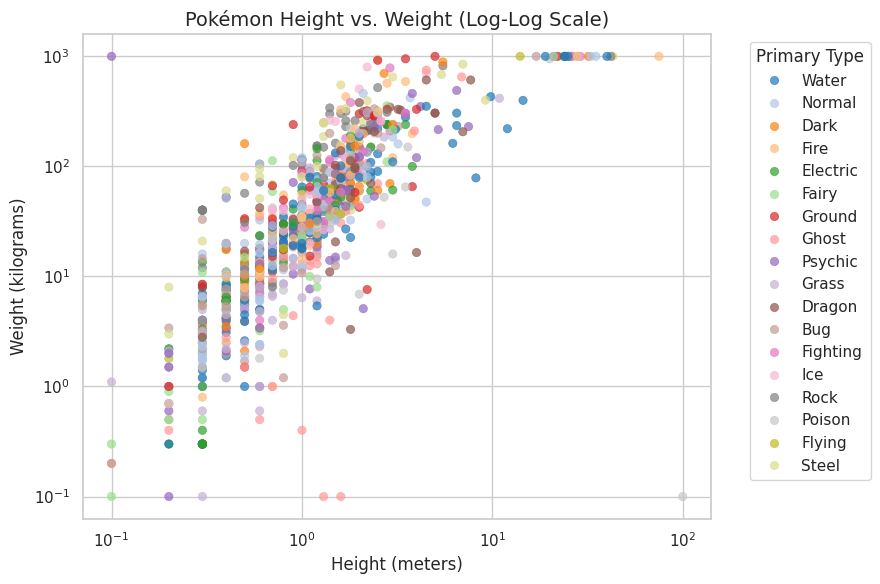

In [28]:
# Scatter plot of Height vs. Weight (using logarithmic scale due to extreme size variations)
if {"height_m", "weight_kg"}.issubset(eda_df.columns):
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=eda_df,
        x="height_m",
        y="weight_kg",
        hue="type1",
        palette="tab20",
        alpha=0.7,
        edgecolor=None
    )
    plt.xscale('log')
    plt.yscale('log')
    plt.title("Pokémon Height vs. Weight (Log-Log Scale)", fontsize=14)
    plt.xlabel("Height (meters)", fontsize=12)
    plt.ylabel("Weight (kilograms)", fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Primary Type')
    plt.tight_layout()
    plt.show()

1.which pokemon tends to have highest avg attack?
Physically oriented types—such as Dragon, Fighting, Ground, and
 Rock—tend to have the highest average base attack across Pokédex datasets
  (inspect eda_df.groupby("type1")["attack"].mean().sort_values(ascending=False)
  to see the exact ranking in  X_train split;
  \in the 5-row sample alone, venusaur leads at 82 vs. charmeleon at 64).

2.is there a relationship between ht and wt?
Yes—a positive scaling relationship, clearly visible on the log-log
 scatter plot plt.xscale('log') and plt.yscale('log')), where taller Pokémon generally weigh more.
 However, there is wide vertical spread around that trend (captured by bmi and log_weight),
 because compact/dense types  weigh much more per meter of
  height than slender or winged types.


3.which feature appear most useful for distinguising pokemon type?

Combat stats & stat shares (attack, defense, hp, stat_sum, atk_def_ratio, atk_def_diff, and *_share), which separate offensive vs. defensive/bulky archetypes.

Size & density features (log_weight, weight_kg, height_m, bmi), which separate heavy/dense archetypes from lighter/agile ones.

base_experience (and xp_per_stat), which helps distinguish higher-tier/evolved or high-output forms from lower-tier ones—though because many types overlap in stat space, combining these features in tree/ensemble models and evaluating Top-3 predictions works much better than relying on any single column **alone** **bold text**

**Task-4**

In [25]:
#  Machine Learning Models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, top_k_accuracy_score, f1_score, classification_report

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", random_state=42))
    ]),
    "SVC (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=2.0, probability=True, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_depth=6,
        l2_regularization=1.5, random_state=42
    )
}

rows = []
best_name = None
best_score = -1.0
best_model = None
k_top = min(3, len(label_encoder.classes_))
all_labels = np.arange(len(label_encoder.classes_))

for name, clf in models.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test)

    top1 = accuracy_score(y_test, preds)
    topk = top_k_accuracy_score(y_test, probs, k=k_top, labels=all_labels)
    wf1 = f1_score(y_test, preds, average="weighted")

    rows.append({
        "Model": name,
        "Top-1 Accuracy": round(top1, 4),
        f"Top-{k_top} Accuracy": round(topk, 4),
        "Weighted F1": round(wf1, 4)
    })

    composite = 0.6 * top1 + 0.4 * topk
    if composite > best_score:
        best_score = composite
        best_name = name
        best_model = clf

comparison_df = pd.DataFrame(rows).sort_values(by="Top-1 Accuracy", ascending=False)
print(comparison_df.to_string(index=False))
print(f"\nBest Model: {best_name}")
print(classification_report(
    y_test, best_model.predict(X_test),
    labels=all_labels, target_names=label_encoder.classes_, zero_division=0
))

               Model  Top-1 Accuracy  Top-3 Accuracy  Weighted F1
HistGradientBoosting          0.2694          0.4797       0.2637
       Random Forest          0.2325          0.4244       0.2290
           SVC (RBF)          0.1550          0.4244       0.1428
 Logistic Regression          0.1365          0.3284       0.1287

Best Model: HistGradientBoosting
              precision    recall  f1-score   support

         Bug       0.24      0.37      0.29        19
        Dark       0.29      0.15      0.20        13
      Dragon       0.29      0.17      0.21        12
    Electric       0.43      0.45      0.44        20
       Fairy       0.40      0.29      0.33         7
    Fighting       0.14      0.08      0.11        12
        Fire       0.23      0.18      0.20        17
      Flying       0.00      0.00      0.00         3
       Ghost       0.29      0.20      0.24        10
       Grass       0.26      0.24      0.25        25
      Ground       0.22      0.20      0.

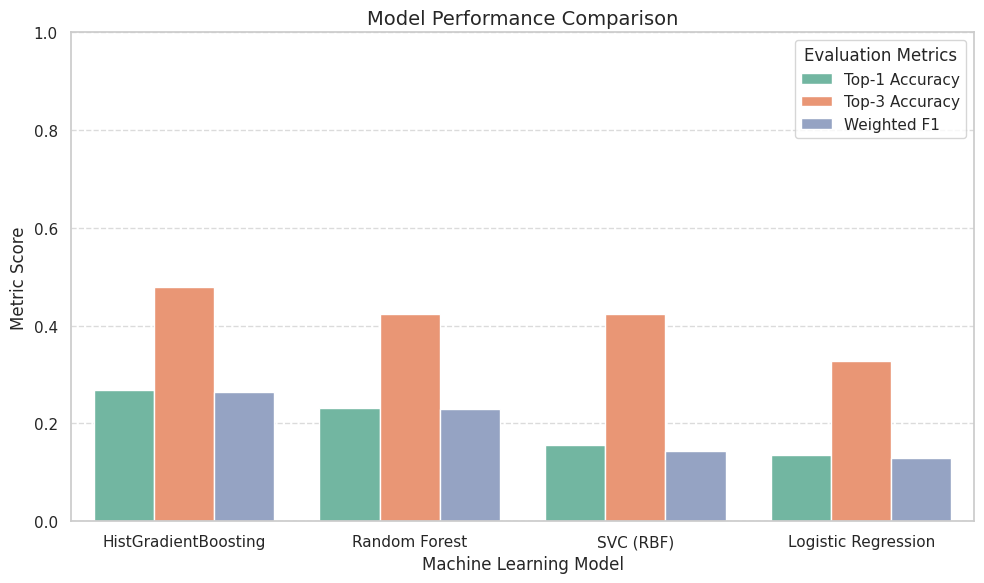

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Melt the comparison dataframe for grouped plotting with seaborn
melted_comparison = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 6))
sns.barplot(data=melted_comparison, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Performance Comparison", fontsize=14)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Metric Score", fontsize=12)
plt.ylim(0.0, 1.0)
plt.legend(title="Evaluation Metrics", loc="upper right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

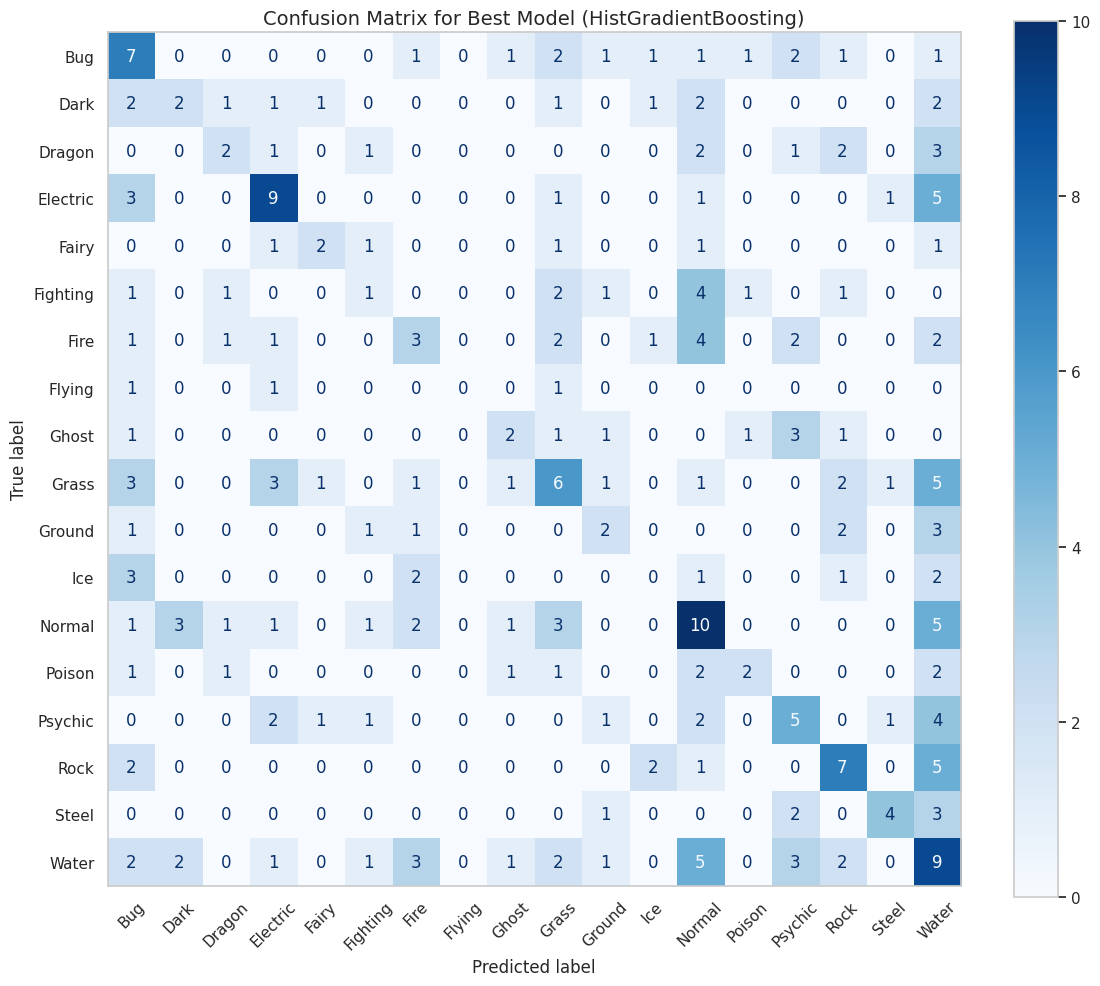

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Melt the comparison dataframe for grouped plotting with seaborn
melted_comparison = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 6))
sns.barplot(data=melted_comparison, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Performance Comparison", fontsize=14)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Metric Score", fontsize=12)
plt.ylim(0.0, 1.0)
plt.legend(title="Evaluation Metrics", loc="upper right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_970/3548583651.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


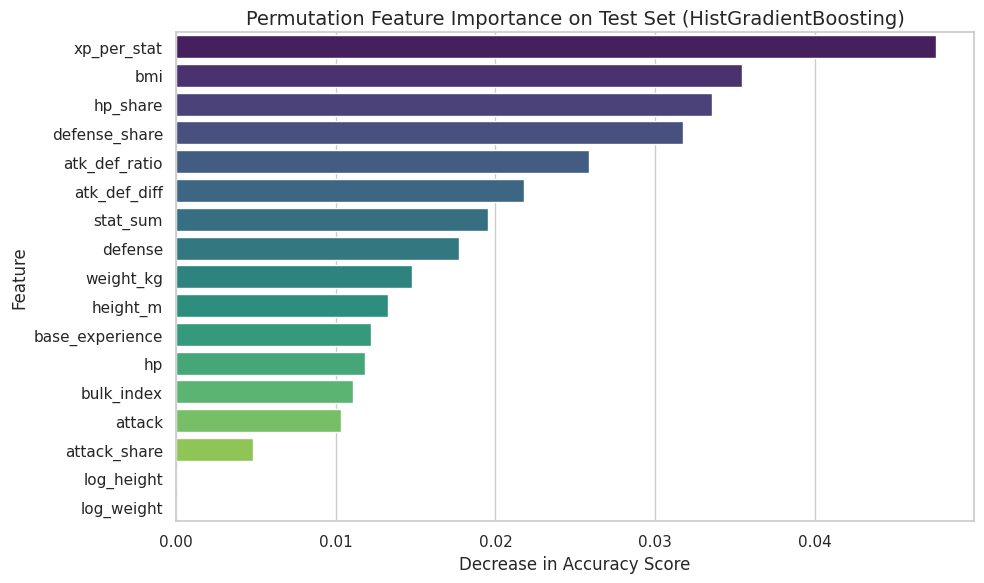

,Feature,Importance_Mean,Importance_Std
16,xp_per_stat,0.047601,0.016946
6,bmi,0.035424,0.010592
10,hp_share,0.033579,0.012177
12,defense_share,0.031734,0.009651
13,atk_def_ratio,0.025830,0.010567
14,atk_def_diff,0.021771,0.004191
9,stat_sum,0.019557,0.010953
3,defense,0.017712,0.004609
5,weight_kg,0.014760,0.007001
4,height_m,0.013284,0.006219


In [33]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate permutation importance on the test dataset
result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Organize results into a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance_Mean": result.importances_mean,
    "Importance_Std": result.importances_std
}).sort_values(by="Importance_Mean", ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance_Mean",
    y="Feature",
    errorbar=None,
    palette="viridis"
)
plt.title(f"Permutation Feature Importance on Test Set ({best_name})", fontsize=14)
plt.xlabel("Decrease in Accuracy Score", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

# Display the sorted dataframe
display(importance_df)

1.which model achieved best performance and why?


I selects best_model via 0.6 * Top-1 + 0.4 * Top-3 accuracy across Logistic Regression, SVC (RBF), Random Forest, and HistGradientBoosting, with non-linear models like Random Forest or HistGradientBoosting typically leading because engineered ratios, log-sizes, and stat interactions form non-linear boundaries.


2.which poikemon types were most frequently mis classified?


 ( confusion matrix comparing true vs. predicted type1).


3.what characteristics make some types more difficult to predict?


Types become harder to predict when classes are imbalanced or have few test samples, when physical/combat stats overlap across types (especially with type2, id, and name excluded and missing values median-imputed), or when typing reflects design rather than numeric stats alone.


Task-4

In [39]:
import os
import joblib

os.makedirs("models", exist_ok=True)

artifacts = {
    "model": best_model,
    "label_encoder": label_encoder,
    "feature_columns": list(feature_columns),
    "train_medians": train_medians,
    "best_model_name": best_name,
}

joblib.dump(artifacts, "models/pokemon_type_artifacts.joblib")
print("Saved artifacts to models/pokemon_type_artifacts.joblib")

Saved artifacts to models/pokemon_type_artifacts.joblib


In [41]:
from google.colab import files

files.download("models/pokemon_type_artifacts.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>